### Imports

In [1]:
import yfinance as yf
import numpy as np
import math
import matplotlib.pyplot as plt
from hmmlearn.hmm import GaussianHMM
from sklearn.model_selection import train_test_split
import pandas as pd

### Data Preparation

In [2]:
stock_universe = "^GSPC"
df = yf.download(stock_universe, start="2005-01-01", end="2025-12-31")
df.columns = df.columns.get_level_values(0)
df.head()

curl_cffi not available; falling back to requests without browser TLS impersonation. Yahoo Finance may rate-limit or block this client. Install curl_cffi (>=0.15) for the supported configuration.
[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Date,,,,,
2005-01-03,1202.079956,1217.800049,1200.319946,1211.920044,1510800000
2005-01-04,1188.050049,1205.839966,1185.390015,1202.079956,1721000000
2005-01-05,1183.739990,1192.729980,1183.719971,1188.050049,1738900000
2005-01-06,1187.890015,1191.630005,1183.270020,1183.739990,1569100000
2005-01-07,1186.189941,1192.199951,1182.160034,1187.890015,1477900000


In [3]:
df['Log Return'] = 100*np.log(df['Close']/df['Close'].shift(1))
df = df.drop_duplicates()
df = df.dropna(how='any')
print("Log Return Stats for S&P : \n", df["Log Return"].agg(["mean", "std", "skew", "kurt"]).round(4))

Log Return Stats for S&P : 
 mean     0.0331
std      1.2087
skew    -0.4777
kurt    13.2237
Name: Log Return, dtype: float64


In [4]:
df.index.duplicated().sum()

np.int64(0)

<Axes: xlabel='Date'>

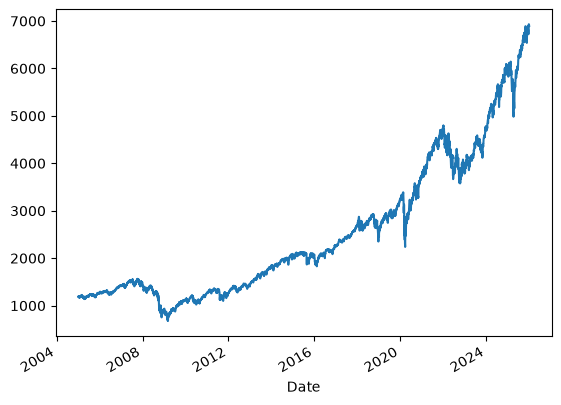

In [5]:
df['Close'].plot()

<Axes: xlabel='Date'>

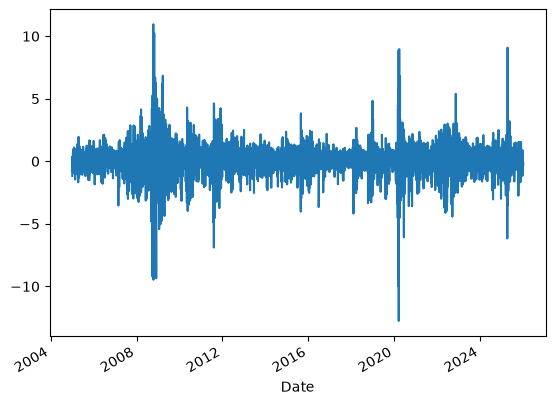

In [6]:
df['Log Return'].plot()

### Model Creation and Training

In [7]:
Y_data = df.loc[:'2019-12-31', 'Log Return'].dropna().to_numpy().reshape(-1, 1)

model = GaussianHMM(n_components=2, covariance_type="diag", n_iter=1000, random_state=42)

model.fit(Y_data)
print("Converged:", model.monitor_.converged)
print("Log-likelihood:", model.score(Y_data))

Converged: True
Log-likelihood: -4983.076966297174


In [8]:
volatilities = np.sqrt(model.covars_.reshape(-1))
low_vol_state = np.argmin(volatilities)
high_vol_state = np.argmax(volatilities)

In [9]:
avg_lasting_low_vol_state = 1/(1-model.transmat_[low_vol_state][low_vol_state])
avg_lasting_high_vol_state = 1/(1-model.transmat_[high_vol_state][high_vol_state])
avg_lasting_low_vol_state, avg_lasting_high_vol_state

(np.float64(64.42466823929001), np.float64(24.02092818343574))

### Training Results

In [11]:
print(f"Low-vol state: {low_vol_state}")
print(f"Daily volatility: {volatilities[low_vol_state]:.3f}%")
print(f"Expected duration: {avg_lasting_low_vol_state} days")

print(f"\nHigh-vol state: {high_vol_state}")
print(f"Daily volatility: {volatilities[high_vol_state]:.3f}%")
print(f"Expected duration: {avg_lasting_high_vol_state} days")

Low-vol state: 0
Daily volatility: 0.632%
Expected duration: 64.42466823929001 days

High-vol state: 1
Daily volatility: 1.963%
Expected duration: 24.02092818343574 days


In [12]:
state_probabilities = model.predict_proba(Y_data)
high_vol_probabilities = state_probabilities[:, high_vol_state]
high_vol_probabilities

array([3.45608051e-12, 4.17119685e-04, 5.00458669e-04, ...,
       1.85017074e-03, 4.63053528e-03, 9.27643740e-03], shape=(3774,))

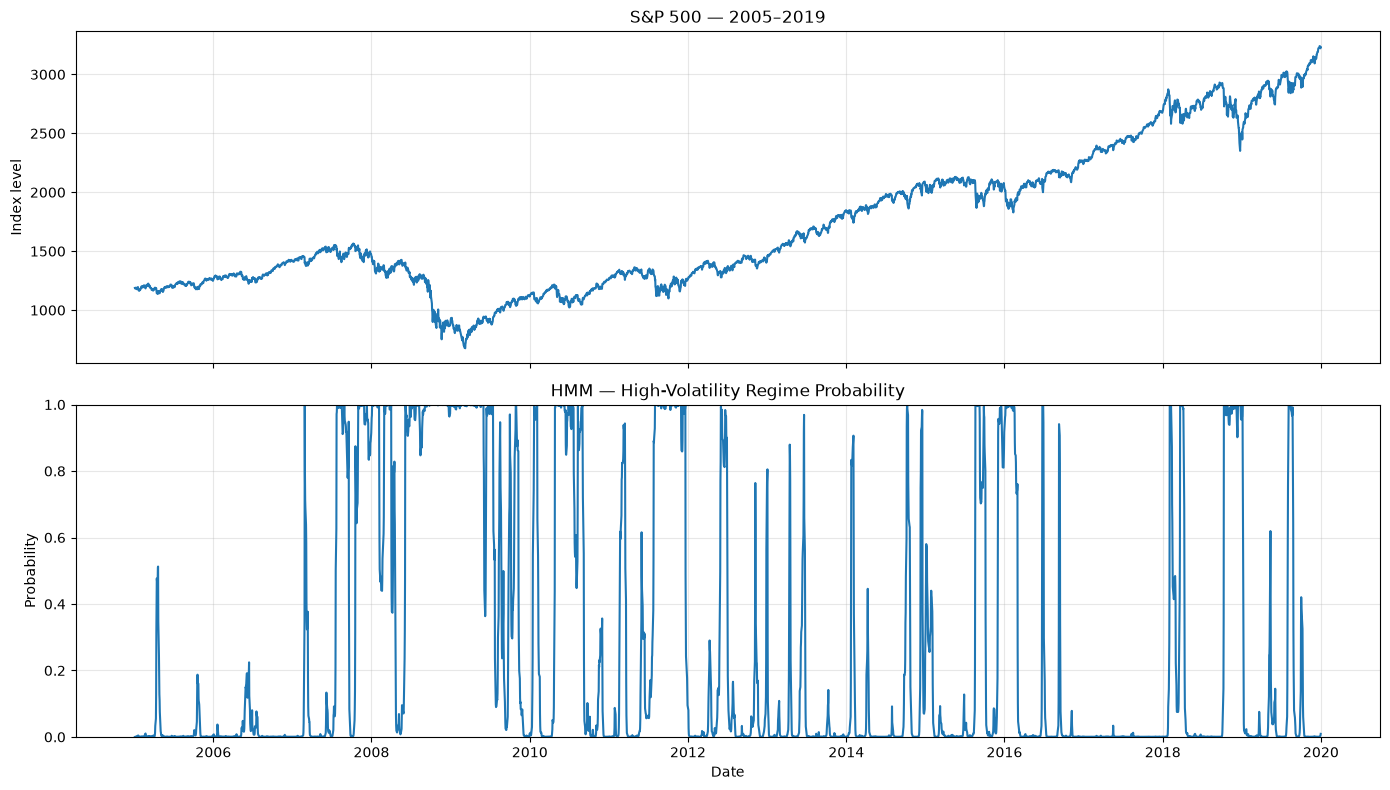

In [14]:
# Training sample: 2005–2019
train_df = df.loc[:'2019-12-31'].dropna(subset=['Log Return'])

# Smoothed probabilities for each hidden state
state_probabilities = model.predict_proba(Y_data)

# High-volatility regime probability, indexed by date
high_vol_proba = pd.Series(
    state_probabilities[:, high_vol_state],
    index=train_df.index,
    name="High-vol probability"
)

# Plot
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# S&P 500 price
axes[0].plot(train_df.index, train_df['Close'])
axes[0].set_title("S&P 500 — 2005–2019")
axes[0].set_ylabel("Index level")
axes[0].grid(alpha=0.3)

# High-vol regime probability
axes[1].plot(high_vol_proba.index, high_vol_proba)
axes[1].set_title("HMM — High-Volatility Regime Probability")
axes[1].set_ylabel("Probability")
axes[1].set_xlabel("Date")
axes[1].set_ylim(0, 1)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

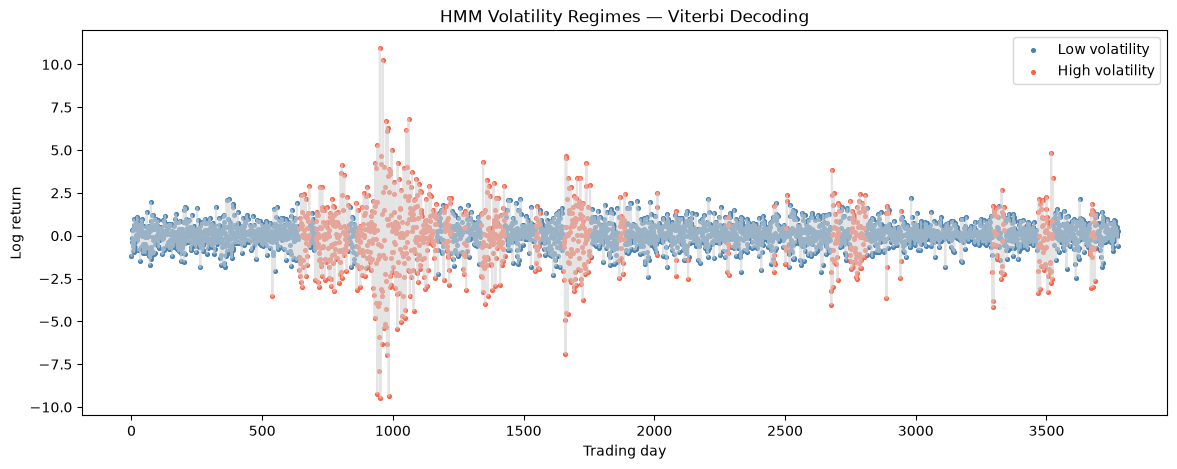

In [33]:
# X : données utilisées pour entraîner le HMM
# Shape attendu : (n_observations, 1)

hidden_states = model.predict(Y_data)

# Identification automatique des régimes
volatilities = np.sqrt(model.covars_.reshape(-1))
low_vol_state = np.argmin(volatilities)
high_vol_state = np.argmax(volatilities)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(Y_data[:, 0], color="lightgray", alpha=0.6)

for state, label, color in [
    (low_vol_state, "Low volatility", "steelblue"),
    (high_vol_state, "High volatility", "tomato")
]:
    mask = hidden_states == state
    ax.scatter(
        np.where(mask)[0],
        Y_data[mask, 0],
        s=7,
        color=color,
        label=label
    )

ax.set_title("HMM Volatility Regimes — Viterbi Decoding")
ax.set_xlabel("Trading day")
ax.set_ylabel("Log return")
ax.legend()
plt.show()